<a href="https://colab.research.google.com/github/Angeltt251/Lab2.12_MLP_MLflow/blob/main/Lab2_12_MLP_MLflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Actividad 2.12 — Laboratorio: Implementación de Redes Neuronales (MLP + MLflow)

**Asignatura:** IEI097 Minería de Datos · Unidad II · Semanas 11–12  
**Autor:** José Miguel Flores Chávez · Instituto Profesional Santo Tomás  
**Número de lista (semilla `SEED`):** el valor de `NUMERO_LISTA` en la primera celda de código  
**Fecha:** 6 de noviembre de 2026  
**Tipo:** laboratorio individual en Google Colab

**Contenido:** 1 Entorno y semilla · 2 Datos · 3 Partición · 4 MLflow en Colab · 5 Experimentos A–D · 6 Semillas y réplica · 7 Análisis y exportación · 8 Cierre

> Las credenciales (`KAGGLE_USERNAME`, `KAGGLE_KEY` y `NGROK_AUTHTOKEN`) se leen desde **Colab Secrets** y nunca se escriben en el notebook.

## Paso 1 · Entorno y semilla personal

In [1]:
!pip install -q mlflow pyngrok

> Si Colab pide reiniciar la sesión, hazlo y vuelve a ejecutar desde el inicio.

In [2]:
import os
import random
import time
import platform
import subprocess
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import kagglehub
import glob
import requests
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score, f1_score, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning

NUMERO_LISTA = 12
assert NUMERO_LISTA is not None, "Escribe tu número de lista en NUMERO_LISTA antes de continuar."

SEED = NUMERO_LISTA
random.seed(SEED)
np.random.seed(SEED)

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

import mlflow

print("SEED:", SEED)
print("python      :", platform.python_version())
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("mlflow      :", mlflow.__version__)

SEED: 12
python      : 3.13.18
numpy       : 2.4.6
pandas      : 2.2.3
scikit-learn: 1.6.1
mlflow      : 3.18.0


## Paso 2 · Carga y preparación de los datos

In [17]:
import os
from google.colab import userdata

try:
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    print("Credenciales de Kaggle cargadas exitosamente ✅")
except Exception:
    print("Información: No se encontraron las credenciales de Kaggle en Colab Secrets. Se utilizará la caché o la descarga directa.")

Información: No se encontraron las credenciales de Kaggle en Colab Secrets. Se utilizará la caché o la descarga directa.


In [4]:
carpeta_bc = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
archivos_bc = sorted(glob.glob(os.path.join(carpeta_bc, "**", "*.csv"), recursive=True))
print("Archivos CSV en la carpeta descargada:")
for a in archivos_bc:
    print(f" - {os.path.relpath(a, carpeta_bc)} ({os.path.getsize(a) / 1e3:.1f} KB)")

csv_bc = max(archivos_bc, key=os.path.getsize)
print("\nCSV principal elegido:", os.path.basename(csv_bc))

df = pd.read_csv(csv_bc)
print("shape:", df.shape)
df.info()

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Archivos CSV en la carpeta descargada:
 - data.csv (125.2 KB)

CSV principal elegido: data.csv
shape: (569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float6

In [5]:
nulos = df.isna().sum()
print("Columnas con nulos:")
print(nulos[nulos > 0].to_string() if (nulos > 0).any() else "ninguna")

columnas_vacias = df.columns[df.isna().all()].tolist()
print("\nColumnas completamente vacías:", columnas_vacias)

Columnas con nulos:
Unnamed: 32    569

Columnas completamente vacías: ['Unnamed: 32']


In [6]:
df = df.drop(columns=[c for c in columnas_vacias + ["id"] if c in df.columns])
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

assert df["diagnosis"].notna().all(), "Hay valores de diagnosis distintos de M o B."
print("shape final:", df.shape)

balance = df["diagnosis"].value_counts().rename({0: "benigno (0)", 1: "maligno (1)"}).to_frame("tumores")
balance["porcentaje"] = (balance["tumores"] / len(df) * 100).round(1)
balance

shape final: (569, 31)


,tumores,porcentaje
diagnosis,,
benigno (0),357,62.7
maligno (1),212,37.3


✍️ **Balance de clases** *(anótalo con tus palabras a partir de la tabla)*

…

In [18]:
VARS_ESCALA = ["radius_mean", "area_mean", "smoothness_mean"]
rangos = df[VARS_ESCALA].agg(["min", "max"]).T
rangos["rango (máx − mín)"] = rangos["max"] - rangos["min"]
display(rangos)

r_mayor = rangos["rango (máx − mín)"].idxmax()
r_menor = rangos["rango (máx − mín)"].idxmin()
veces = rangos.loc[r_mayor, "rango (máx − mín)"] / rangos.loc[r_menor, "rango (máx − mín)"]
print(f"El rango de {r_mayor} es {veces:,.0f} veces el de {r_menor}.")

,min,max,rango (máx − mín)
radius_mean,6.98100,28.1100,21.12900
area_mean,143.50000,2501.0000,2357.50000
smoothness_mean,0.05263,0.1634,0.11077


El rango de area_mean es 21,283 veces el de smoothness_mean.


## Paso 3 · Partición estratificada

Una sola partición para todo el laboratorio: así, cualquier diferencia entre ejecuciones se debe solo al cambio que introduzco (un cambio a la vez).

In [8]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

proporciones = pd.DataFrame({
    "completo": y.value_counts(normalize=True),
    "entrenamiento": y_train.value_counts(normalize=True),
    "prueba": y_test.value_counts(normalize=True),
}).rename(index={0: "benigno (0)", 1: "maligno (1)"})

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
(proporciones * 100).round(2)

X_train: (455, 30) | X_test: (114, 30)


,completo,entrenamiento,prueba
diagnosis,,,
benigno (0),62.74,62.64,63.16
maligno (1),37.26,37.36,36.84


## Paso 4 · MLflow en Colab

Antes de ejecutar la celda siguiente, guarda tu authtoken de ngrok en Colab Secrets (ícono 🔑) con el nombre `NGROK_AUTHTOKEN` y activa «Acceso desde el notebook».

> ⚠️ **Seguridad:** mientras el túnel esté abierto, el servidor MLflow es accesible desde Internet sin contraseña y con la validación de hosts desactivada. Es aceptable solo en este laboratorio: la URL es temporal y los datos son públicos. Cierro el túnel en el paso 8.
>
> ⚠️ **No ejecutes la celda del servidor dos veces seguidas.** Si aparece `ERR_NGROK_108`, tu cuenta ya tiene otra sesión de ngrok abierta: ciérrala.

In [21]:
from pyngrok import ngrok
from google.colab import userdata

URI_MLFLOW = "http://127.0.0.1:4500"
entorno_servidor = dict(os.environ, MLFLOW_SERVER_ALLOWED_HOSTS="*", MLFLOW_SERVER_CORS_ALLOWED_ORIGINS="*")

registro_servidor = open("mlflow_server.log", "w")
subprocess.Popen(["mlflow", "server", "--backend-store-uri", "sqlite:///mlflow.db", "--host", "127.0.0.1", "--port", "4500"],
                 env=entorno_servidor, stdout=registro_servidor, stderr=subprocess.STDOUT)

servidor_listo = False
for _ in range(60):
    try:
        if requests.get(f"{URI_MLFLOW}/health", timeout=1).ok:
            servidor_listo = True
            break
    except requests.RequestException:
        pass
    time.sleep(1)

if not servidor_listo:
    print("El servidor MLflow no respondió en 60 s. Últimas líneas del registro:")
    print("".join(open("mlflow_server.log").readlines()[-15:]))
else:
    print("Servidor MLflow iniciado localmente en:", URI_MLFLOW)
    try:
        token = userdata.get("NGROK_AUTHTOKEN")
        ngrok.set_auth_token(token)
        ngrok.kill()
        tunel = ngrok.connect(4500)
        print("MLflow UI (Pública vía ngrok):", tunel.public_url)
    except Exception as e:
        print("No se pudo crear el túnel de ngrok (puedes ignorar esto si solo usas el backend local). Detalle:", type(e).__name__)

Servidor MLflow iniciado localmente en: http://127.0.0.1:4500
No se pudo crear el túnel de ngrok (puedes ignorar esto si solo usas el backend local). Detalle: SecretNotFoundError


Abre la URL impresa. Si ngrok muestra una página de aviso, presiona «Visit Site». Debes ver la interfaz de MLflow, todavía sin ejecuciones.

In [22]:
NOMBRE_EXPERIMENTO = "IEI097-L2.12-Flores"

mlflow.set_tracking_uri(URI_MLFLOW)
experimento = mlflow.set_experiment(NOMBRE_EXPERIMENTO)
print("Experimento:", experimento.name, "| id:", experimento.experiment_id)

2026/11/06 03:33:30 INFO mlflow.tracking.fluent: Experiment with name 'IEI097-L2.12-Flores' does not exist. Creating a new experiment.


Experimento: IEI097-L2.12-Flores | id: 1


## Paso 5 · Experimentos controlados: un cambio a la vez

### Función reutilizable

`correr_experimento` entrena el modelo (con el escalado dentro de un `Pipeline`, ajustado solo con entrenamiento) y registra en MLflow:

- **Parámetros:** arquitectura, activación, alpha, `max_iter`, `random_state` del modelo, escalado, semilla de la partición y tasa de aprendizaje.
- **Métricas:** exactitud en entrenamiento y prueba, sensibilidad (recall) de la clase maligna, F1 de la clase maligna, iteraciones realizadas y si convergió.
- **Pérdida por época:** `train_loss`, con `step`.
- **Artefacto:** matriz de confusión del conjunto de prueba (`matriz_confusion.png`).
- **Etiqueta:** `fase`.

In [23]:
resultados = {}


def correr_experimento(clave, nombre_run, fase, escalar, capas, activacion, alpha=1e-4, max_iter=500,
                       semilla_modelo=SEED, learning_rate_init=1e-3, mostrar=True):
    pasos = [("escalador", StandardScaler() if escalar else "passthrough"),
             ("mlp", MLPClassifier(hidden_layer_sizes=capas, activation=activacion, alpha=alpha, max_iter=max_iter,
                                   learning_rate_init=learning_rate_init, random_state=semilla_modelo))]
    modelo = Pipeline(pasos)

    with mlflow.start_run(run_name=nombre_run) as run:
        mlflow.set_tag("fase", fase)
        mlflow.log_params({
            "capas": str(capas),
            "activacion": activacion,
            "alpha": alpha,
            "max_iter": max_iter,
            "random_state": semilla_modelo,
            "escalado": "si" if escalar else "no",
            "semilla_particion": SEED,
            "learning_rate_init": learning_rate_init,
        })

        modelo.fit(X_train, y_train)
        mlp = modelo.named_steps["mlp"]
        pred_train = modelo.predict(X_train)
        pred_test = modelo.predict(X_test)

        metricas = {
            "exactitud_train": accuracy_score(y_train, pred_train),
            "exactitud_test": accuracy_score(y_test, pred_test),
            "recall_maligno": recall_score(y_test, pred_test, pos_label=1),
            "f1_maligno": f1_score(y_test, pred_test, pos_label=1),
            "iteraciones": mlp.n_iter_,
            "convergio": int(mlp.n_iter_ < max_iter),
        }
        mlflow.log_metrics(metricas)
        for epoca, perdida in enumerate(mlp.loss_curve_, start=1):
            mlflow.log_metric("train_loss", float(perdida), step=epoca)

        fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
        ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["benigno", "maligno"], ax=ejes[0], colorbar=False)
        ejes[0].set_title(f"Matriz de confusión (prueba)\n{nombre_run}")
        ejes[1].plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_)
        ejes[1].set_xlabel("Época")
        ejes[1].set_ylabel("train_loss")
        ejes[1].set_title("Pérdida por época")
        plt.tight_layout()
        fig_matriz, ax_matriz = plt.subplots(figsize=(4.2, 4))
        ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["benigno", "maligno"], ax=ax_matriz, colorbar=False)
        ax_matriz.set_title(f"Matriz de confusión (prueba)\n{nombre_run}")
        mlflow.log_figure(fig_matriz, "matriz_confusion.png")
        plt.close(fig_matriz)
        if mostrar:
            plt.show()
        plt.close(fig)

        falsos_negativos = int(((y_test == 1) & (pred_test == 0)).sum())
        resultados[clave] = {"run": nombre_run, "fase": fase, "run_id": run.info.run_id,
                             "falsos_negativos": falsos_negativos, **metricas}

    linea = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in resultados[clave].items() if k not in ("run_id",)}
    print(linea)
    return resultados[clave]

### Run A · sin escalado, (30,), relu — punto de partida

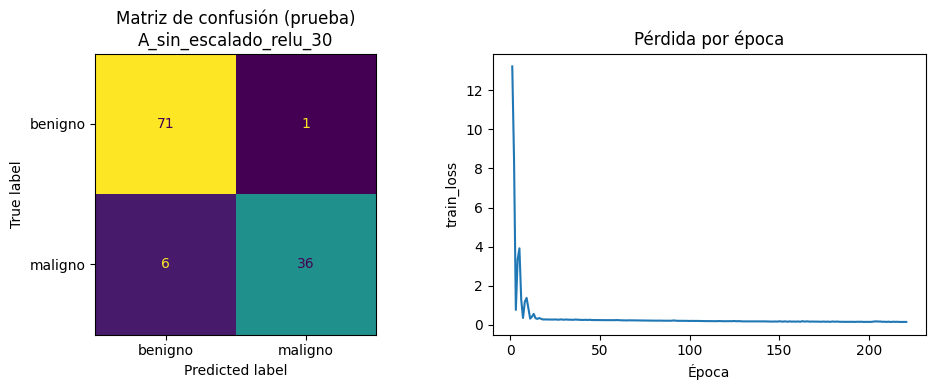

🏃 View run A_sin_escalado_relu_30 at: http://127.0.0.1:4500/#/experiments/1/runs/b1bf2ae44f024dfa9de9a1de1ee916a4
🧪 View experiment at: http://127.0.0.1:4500/#/experiments/1
{'run': 'A_sin_escalado_relu_30', 'fase': 'experimentos', 'falsos_negativos': 6, 'exactitud_train': 0.9451, 'exactitud_test': 0.9386, 'recall_maligno': 0.8571, 'f1_maligno': 0.9114, 'iteraciones': 221, 'convergio': 1}


{'run': 'A_sin_escalado_relu_30',
 'fase': 'experimentos',
 'run_id': 'b1bf2ae44f024dfa9de9a1de1ee916a4',
 'falsos_negativos': 6,
 'exactitud_train': 0.945054945054945,
 'exactitud_test': 0.9385964912280702,
 'recall_maligno': 0.8571428571428571,
 'f1_maligno': 0.9113924050632911,
 'iteraciones': 221,
 'convergio': 1}

In [24]:
correr_experimento("A", "A_sin_escalado_relu_30", "experimentos", escalar=False, capas=(30,), activacion="relu")

### Run B · con escalado, (30,), relu — se agrega escalado

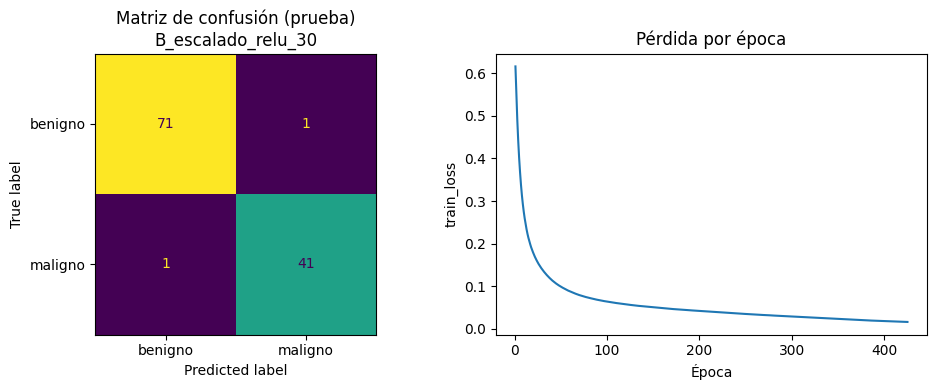

🏃 View run B_escalado_relu_30 at: http://127.0.0.1:4500/#/experiments/1/runs/1fdd14276a99447b9df22b5706154dd0
🧪 View experiment at: http://127.0.0.1:4500/#/experiments/1
{'run': 'B_escalado_relu_30', 'fase': 'experimentos', 'falsos_negativos': 1, 'exactitud_train': 0.9934, 'exactitud_test': 0.9825, 'recall_maligno': 0.9762, 'f1_maligno': 0.9762, 'iteraciones': 425, 'convergio': 1}


{'run': 'B_escalado_relu_30',
 'fase': 'experimentos',
 'run_id': '1fdd14276a99447b9df22b5706154dd0',
 'falsos_negativos': 1,
 'exactitud_train': 0.9934065934065934,
 'exactitud_test': 0.9824561403508771,
 'recall_maligno': 0.9761904761904762,
 'f1_maligno': 0.9761904761904762,
 'iteraciones': 425,
 'convergio': 1}

In [25]:
correr_experimento("B", "B_escalado_relu_30", "experimentos", escalar=True, capas=(30,), activacion="relu")

### Run C · con escalado, (64, 32), relu — cambia la arquitectura

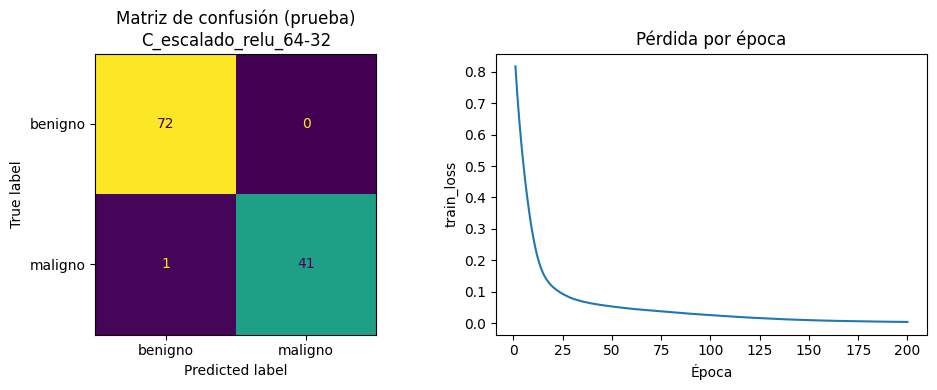

🏃 View run C_escalado_relu_64-32 at: http://127.0.0.1:4500/#/experiments/1/runs/41ddf972f0d3492180263bb9acb2c724
🧪 View experiment at: http://127.0.0.1:4500/#/experiments/1
{'run': 'C_escalado_relu_64-32', 'fase': 'experimentos', 'falsos_negativos': 1, 'exactitud_train': 1.0, 'exactitud_test': 0.9912, 'recall_maligno': 0.9762, 'f1_maligno': 0.988, 'iteraciones': 200, 'convergio': 1}


{'run': 'C_escalado_relu_64-32',
 'fase': 'experimentos',
 'run_id': '41ddf972f0d3492180263bb9acb2c724',
 'falsos_negativos': 1,
 'exactitud_train': 1.0,
 'exactitud_test': 0.9912280701754386,
 'recall_maligno': 0.9761904761904762,
 'f1_maligno': 0.9879518072289156,
 'iteraciones': 200,
 'convergio': 1}

In [26]:
correr_experimento("C", "C_escalado_relu_64-32", "experimentos", escalar=True, capas=(64, 32), activacion="relu")

### Run D · con escalado, (64, 32), tanh — cambia la función de activación

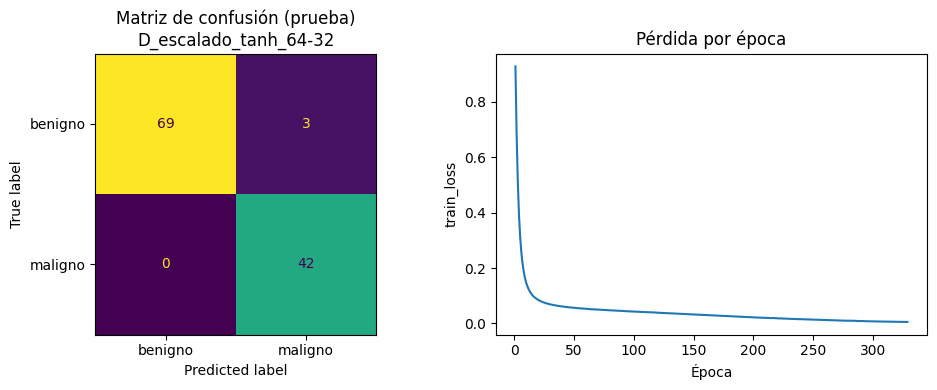

🏃 View run D_escalado_tanh_64-32 at: http://127.0.0.1:4500/#/experiments/1/runs/64488bfa7fa44c18ae07282cbca4e2ad
🧪 View experiment at: http://127.0.0.1:4500/#/experiments/1
{'run': 'D_escalado_tanh_64-32', 'fase': 'experimentos', 'falsos_negativos': 0, 'exactitud_train': 1.0, 'exactitud_test': 0.9737, 'recall_maligno': 1.0, 'f1_maligno': 0.9655, 'iteraciones': 329, 'convergio': 1}


{'run': 'D_escalado_tanh_64-32',
 'fase': 'experimentos',
 'run_id': '64488bfa7fa44c18ae07282cbca4e2ad',
 'falsos_negativos': 0,
 'exactitud_train': 1.0,
 'exactitud_test': 0.9736842105263158,
 'recall_maligno': 1.0,
 'f1_maligno': 0.9655172413793104,
 'iteraciones': 329,
 'convergio': 1}

In [27]:
correr_experimento("D", "D_escalado_tanh_64-32", "experimentos", escalar=True, capas=(64, 32), activacion="tanh")

### Opcional · variar `alpha` y `learning_rate_init` sobre la configuración C

In [28]:
correr_experimento("E", "E_alpha_0.01", "experimentos", escalar=True, capas=(64, 32), activacion="relu", alpha=1e-2, mostrar=False)
correr_experimento("F", "F_lr_0.01", "experimentos", escalar=True, capas=(64, 32), activacion="relu", learning_rate_init=1e-2, mostrar=False)

🏃 View run E_alpha_0.01 at: http://127.0.0.1:4500/#/experiments/1/runs/a10406b1919f416baa19c055ebcefe43
🧪 View experiment at: http://127.0.0.1:4500/#/experiments/1
{'run': 'E_alpha_0.01', 'fase': 'experimentos', 'falsos_negativos': 1, 'exactitud_train': 1.0, 'exactitud_test': 0.9912, 'recall_maligno': 0.9762, 'f1_maligno': 0.988, 'iteraciones': 230, 'convergio': 1}
🏃 View run F_lr_0.01 at: http://127.0.0.1:4500/#/experiments/1/runs/dbbfdeaa54394274891b4af4ec6d5db3
🧪 View experiment at: http://127.0.0.1:4500/#/experiments/1
{'run': 'F_lr_0.01', 'fase': 'experimentos', 'falsos_negativos': 1, 'exactitud_train': 1.0, 'exactitud_test': 0.9825, 'recall_maligno': 0.9762, 'f1_maligno': 0.9762, 'iteraciones': 64, 'convergio': 1}


{'run': 'F_lr_0.01',
 'fase': 'experimentos',
 'run_id': 'dbbfdeaa54394274891b4af4ec6d5db3',
 'falsos_negativos': 1,
 'exactitud_train': 1.0,
 'exactitud_test': 0.9824561403508771,
 'recall_maligno': 0.9761904761904762,
 'f1_maligno': 0.9761904761904762,
 'iteraciones': 64,
 'convergio': 1}

### Resumen de los runs de este paso

In [29]:
resumen_5 = pd.DataFrame([resultados[k] for k in ["A", "B", "C", "D", "E", "F"]]).drop(columns=["run_id", "fase"])
resumen_5.round(4)

,run,falsos_negativos,exactitud_train,exactitud_test,recall_maligno,f1_maligno,iteraciones,convergio
0,A_sin_escalado_relu_30,6,0.9451,0.9386,0.8571,0.9114,221,1
1,B_escalado_relu_30,1,0.9934,0.9825,0.9762,0.9762,425,1
2,C_escalado_relu_64-32,1,1.0000,0.9912,0.9762,0.9880,200,1
3,D_escalado_tanh_64-32,0,1.0000,0.9737,1.0000,0.9655,329,1
4,E_alpha_0.01,1,1.0000,0.9912,0.9762,0.9880,230,1
5,F_lr_0.01,1,1.0000,0.9825,0.9762,0.9762,64,1


Actualizo la interfaz de MLflow y compruebo que cada run aparece con sus parámetros y métricas. **Capturas de pantalla:** tomo las capturas a medida que avanzo (ver el paso 7).

## Paso 6 · Semilla y replicación

### Variabilidad: la configuración C con 5 semillas del modelo

La partición queda fija. Las semillas son `SEED`, `SEED+1`, …, `SEED+4`.

In [30]:
resultados_semillas = []
for s in range(SEED, SEED + 5):
    r = correr_experimento(f"C_semilla_{s}", f"C_semilla_{s}", "semillas", escalar=True, capas=(64, 32), activacion="relu",
                           semilla_modelo=s, mostrar=False)
    resultados_semillas.append(r)

tabla_semillas = pd.DataFrame(resultados_semillas)[["run", "exactitud_train", "exactitud_test", "recall_maligno", "f1_maligno", "iteraciones", "falsos_negativos"]]
tabla_semillas.round(4)

🏃 View run C_semilla_12 at: http://127.0.0.1:4500/#/experiments/1/runs/ed1e97b4716e4a52858db079c739b397
🧪 View experiment at: http://127.0.0.1:4500/#/experiments/1
{'run': 'C_semilla_12', 'fase': 'semillas', 'falsos_negativos': 1, 'exactitud_train': 1.0, 'exactitud_test': 0.9912, 'recall_maligno': 0.9762, 'f1_maligno': 0.988, 'iteraciones': 200, 'convergio': 1}
🏃 View run C_semilla_13 at: http://127.0.0.1:4500/#/experiments/1/runs/0dd33099ba7348afba3acd8a1189ba95
🧪 View experiment at: http://127.0.0.1:4500/#/experiments/1
{'run': 'C_semilla_13', 'fase': 'semillas', 'falsos_negativos': 1, 'exactitud_train': 1.0, 'exactitud_test': 0.9825, 'recall_maligno': 0.9762, 'f1_maligno': 0.9762, 'iteraciones': 214, 'convergio': 1}
🏃 View run C_semilla_14 at: http://127.0.0.1:4500/#/experiments/1/runs/488684d8756f41a78957420e25f56314
🧪 View experiment at: http://127.0.0.1:4500/#/experiments/1
{'run': 'C_semilla_14', 'fase': 'semillas', 'falsos_negativos': 1, 'exactitud_train': 1.0, 'exactitud_test'

,run,exactitud_train,exactitud_test,recall_maligno,f1_maligno,iteraciones,falsos_negativos
0,C_semilla_12,1.0000,0.9912,0.9762,0.9880,200,1
1,C_semilla_13,1.0000,0.9825,0.9762,0.9762,214,1
2,C_semilla_14,1.0000,0.9912,0.9762,0.9880,197,1
3,C_semilla_15,0.9978,0.9825,0.9762,0.9762,202,1
4,C_semilla_16,1.0000,0.9737,0.9762,0.9647,202,1


In [31]:
variacion = pd.DataFrame({
    "mínimo": tabla_semillas[["exactitud_test", "recall_maligno"]].min(),
    "máximo": tabla_semillas[["exactitud_test", "recall_maligno"]].max(),
})
variacion["rango"] = variacion["máximo"] - variacion["mínimo"]
variacion.round(4)

,mínimo,máximo,rango
exactitud_test,0.9737,0.9912,0.0175
recall_maligno,0.9762,0.9762,0.0000


### Replicación: la configuración C con la semilla original

Ejecuto de nuevo la configuración C con `SEED` (etiqueta `fase = replica`) y comparo con el run C.

In [ ]:
correr_experimento("replica", f"C_replica_semilla_{SEED}", "replica", escalar=True, capas=(64, 32), activacion="relu",
                   semilla_modelo=SEED, mostrar=False)

claves_metricas = ["exactitud_train", "exactitud_test", "recall_maligno", "f1_maligno", "iteraciones"]
comparacion_replica = pd.DataFrame({
    "run C": [resultados["C"][k] for k in claves_metricas],
    "réplica": [resultados["replica"][k] for k in claves_metricas],
}, index=claves_metricas)
comparacion_replica["diferencia absoluta"] = (comparacion_replica["run C"] - comparacion_replica["réplica"]).abs()

print("Diferencia máxima entre el run C y la réplica:", comparacion_replica["diferencia absoluta"].max())
comparacion_replica

## Paso 7 · Análisis de las ejecuciones y exportación de la evidencia

### En la interfaz de MLflow (con la URL de ngrok visible en la barra de direcciones)

- [ ] Ordenar la tabla del experimento por `recall_maligno` y comprobar que hay al menos 10 runs → **captura 1**.
- [ ] Seleccionar al menos 4 runs y usar **Compare**; observar `train_loss` de al menos dos runs superpuestos → **captura 2**.
- [ ] Abrir una ejecución y ubicar el artefacto `matriz_confusion.png` → **captura 3**.
- [ ] Mostrar dos runs con la misma semilla y métricas idénticas en la tabla (run C y su réplica).

### En el notebook

In [ ]:
runs_crudos = mlflow.search_runs(experiment_names=[NOMBRE_EXPERIMENTO])
print("Runs encontrados en MLflow:", len(runs_crudos))

nombres_columnas = {
    "tags.mlflow.runName": "run",
    "tags.fase": "fase",
    "params.escalado": "escalado",
    "params.capas": "capas",
    "params.activacion": "activacion",
    "params.alpha": "alpha",
    "params.learning_rate_init": "learning_rate_init",
    "params.random_state": "semilla_modelo",
    "params.semilla_particion": "semilla_particion",
    "metrics.exactitud_train": "exactitud_train",
    "metrics.exactitud_test": "exactitud_test",
    "metrics.recall_maligno": "recall_maligno",
    "metrics.f1_maligno": "f1_maligno",
    "metrics.iteraciones": "iteraciones",
    "metrics.convergio": "convergio",
    "metrics.train_loss": "train_loss_final",
}
runs_df = (runs_crudos[[c for c in nombres_columnas if c in runs_crudos.columns]]
           .rename(columns=nombres_columnas)
           .sort_values("recall_maligno", ascending=False)
           .reset_index(drop=True))

assert len(runs_df) >= 10, f"Hay {len(runs_df)} runs: la actividad pide al menos 10."
runs_df.to_csv("runs.csv", index=False)
print("Exportado: runs.csv")
runs_df.round(4)

In [ ]:
from google.colab import files
files.download("runs.csv")

## Paso 8 · Cierre

### Datos de apoyo para las preguntas de cierre

Calculados a partir de mis propias ejecuciones.

In [ ]:
diferencia_AB = {k: resultados["B"][k] - resultados["A"][k] for k in ["exactitud_train", "exactitud_test", "recall_maligno", "f1_maligno"]}
print("Pregunta 1: B − A (efecto del escalado)")
print({k: round(v, 4) for k, v in diferencia_AB.items()})
print("Iteraciones A vs. B:", resultados["A"]["iteraciones"], "vs.", resultados["B"]["iteraciones"],
      "| convergió A:", bool(resultados["A"]["convergio"]), "| convergió B:", bool(resultados["B"]["convergio"]))

print("\nPreguntas 2 y 3: variación entre semillas vs. diferencias entre configuraciones (B, C, D)")
configs = pd.DataFrame([resultados[k] for k in ["B", "C", "D"]]).set_index("run")[["exactitud_test", "recall_maligno"]]
entre_configs = configs.max() - configs.min()
entre_semillas = variacion["rango"]
display(pd.DataFrame({"rango entre configuraciones B, C y D": entre_configs, "rango entre 5 semillas (config. C)": entre_semillas}).round(4))

print("Falsos negativos en prueba:", {k: resultados[k]["falsos_negativos"] for k in ["A", "B", "C", "D"]})

### Cierre del túnel

In [ ]:
ngrok.kill()
print("Túnel de ngrok cerrado.")

> **Sesión efímera:** al cerrar o desconectar Colab se pierde `mlflow.db` y, con él, todas las ejecuciones. Antes de cerrar: `runs.csv` descargado, capturas tomadas y notebook sincronizado en GitHub junto con `runs.csv` y la carpeta `evidencias/`.